# _Python for Scientific Data Analysis_


#  AstroPy and AstroQuery

## Section 3: AstroQuery

## (_Note_ : Outages Affecting Astroquery) 

Currently -- 11/17/2026 -- CDS is experiencing a major outage.  It has wrecked havoc on my notes: fixing the notes has taken some time. The entire astroquery infrastructure is affected: I include information about mirror sites as a result.  It is possible that further outages will occur: please save a copy of this notebook so you can see the output when the queries are working.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import astroquery

from astropy.coordinates import Angle

In [2]:
from astroquery.simbad import Simbad #Simbad astronomical database
from astroquery.vizier import Vizier #Vizier database

### Vizier

### Some Examples of Doing Science with Database Queries

So how would you actually use this in real code?   Below is one example: 
* an abbreviated example copied and pasted from some code that I wrote two years ago to select targets.  It has an input file and then queries the Simbad and Vizier databases

  

In [3]:
#uses IDL output of HGCA accelerators, queries Simbad to get the spectral type, queries Gaia-eDR3 to get photometry, saves to output
import astroquery
import numpy as np
from astroquery.simbad import Simbad
from astroquery.vizier import Vizier
from astropy.io import ascii
import astropy.units as u
import astropy.coordinates as coord
from astropy.table import QTable
#from astroquery.utils.tap.core import TapPlus
from astroquery.gaia import Gaia
from astropy.coordinates import SkyCoord,Angle

infile='astars_100pc'
Gaia.MAIN_GAIA_TABLE = "gaiaedr3.gaia_source"
radius=u.Quantity(1.5/3600.0,u.deg)

def add_gaia_data(infile,vizurl='vizier.cfa.harvard.edu',gaiacat=None):



        #Simbad.server='simbad.harvard.edu' #for astroquery 0.4.11 this works
    Simbad.SIMBAD_URL = 'https://simbad.harvard.edu/simbad/sim-script' #for astroquery 0.4.7 you need to do this

    Vizier.VIZIER_SERVER = vizurl #because CDS is still down
    Vizier.TIMEOUT = 20

    outfile=infile+'_plus_gaia_and_cahkv2'

    #formatted loading
    dtypes={'names': ('name1','name2','ra1','ra2','ra3','dec1','dec2','dec3','distance','spt','mass','chisq'),\
       'formats':('U20','U20',np.int64,np.int64,np.float64,np.int64,np.int64,np.float64,np.float64,'U20',np.float64,np.float64)}

    a= np.loadtxt(infile,usecols=range(12),dtype=dtypes)

    #combining the first two strings to get the target name
    names = np.array([ '{0} {1}'.format( x, y ) for x,y in zip( a['name1'], a['name2'] ) ])
    names =np.array(names,dtype=str)

    mass=a['mass']
    chisq=a['chisq']
    #determine ra and dec
    ra_deg=(a['ra1']+a['ra2']/60.+a['ra3']/3600.)*15
    dec_deg=(np.abs(a['dec1'])+np.abs(a['dec2']/60.)+np.abs(a['dec3']/3600.))

    pos = a['dec1'] >= 0
    neg = (a['dec1'] < 0) | (a['dec2'] < 0)
    print(len(neg))
    dec_deg[neg]=-1*dec_deg[neg]


    nstar=len(dec_deg)

    plx=np.zeros(nstar)
    gmag=np.zeros(nstar)
    bp_rp=np.zeros(nstar)
    ra=np.zeros(nstar)
    dec=np.zeros(nstar)
    bmv=np.zeros(nstar)
    hkact=np.zeros(nstar)

    Simbad.add_votable_fields('sptype')
    Simbad.timeout=60
    Vizier.timeout=60

    spt= ["" for i in range(nstar)]

    for i in range(nstar):
       print('processing star number ',i,' star name ',names[i])

       #simbad
       try:
        results=Simbad.query_object(names[i])
       except:
        print('!!!!!Error on ',names[i])
        continue
       spt[i]=results['SP_TYPE'][0]

       coord=SkyCoord(ra=ra_deg[i],dec=dec_deg[i],unit=(u.degree,u.degree),frame='icrs')

       if gaiacat is not None: 
        r=Gaia.cone_search(coord,radius=radius)
        j=r.get_results()
        try:
          ra[i]=j['ra'][0]
          dec[i]=j['dec'][0]
          plx[i]=j['parallax'][0]
          gmag[i]=j['phot_g_mean_mag'][0]
          bp_rp[i]=j['bp_rp'][0]  
#         print('found star ',i,names[i],ra_deg[i],dec_deg[i],(a['dec1'])[i],(a['dec2'])[i],(a['dec3'])[i])
        except:
          print('missing star ',i,names[i],ra_deg[i],dec_deg[i],(a['dec1'])[i],(a['dec2'])[i],(a['dec3'])[i])
          continue
       else:
         j=Vizier.query_region(coord,radius=Angle(1.5, "arcsec"),catalog='I/355/gaiadr3')  

         try:  

          ra[i]=j[0]['RA_ICRS'][0]
          dec[i]=j[0]['DE_ICRS'][0]
          plx[i]=j[0]['Plx'][0] 
          gmag[i]=j[0]['Gmag'][0]   
          bp_rp[i]=j[0]['BP-RP'][0]   
         except:
          print('missing star2 ',i,names[i],ra_deg[i],dec_deg[i],(a['dec1'])[i],(a['dec2'])[i],(a['dec3'])[i])
          exit(1)   
          continue
             

       print('the right ascension and declination are {0} and {1}'.format(ra[i],dec[i]))
        
       #now, pull Tycho II catalog
       #result=Vizier.query_region(SkyCoord.from_name(names[i]),radius=Angle(5/3600.,"deg"),catalog=['I/259/tyc2'])
       #cpos = SkyCoord.from_name(names[i])
        
       result=Vizier.query_region(SkyCoord.from_name(names[i]),radius=Angle(5/3600.,"deg"),catalog=['I/259/tyc2']) 
       #result=Vizier.query_object(names[i],radius=Angle(5/3600.,"deg"),catalog=['I/259/tyc2'])
        
       #print(result)
       #result=Vizier.query_object(names[i],radius=Angle(5/3600.,"deg"),catalog=['I/259/tyc2'])
       #print(result[0]['BTmag'][0])

       if len(result) >= 1:
         btmag=result[0]['BTmag'][0]
         vtmag=result[0]['VTmag'][0]
         bmag,vmag=tycho_convert(btmag,vtmag)
         #print(bmag,vmag,btmag,vtmag)
       else:
         bmag= -99
         vmag=-109

       caHK=99 #initializing to NaN


       #now, pull catalogs to find if the star has an activity measurement
       #Pace+2013
       result=Vizier.query_object(names[i],radius=Angle(5/3600.,"deg"),catalog=['J/A+A/551/L8'])
       try:
        for t in result:
         if 'logRmin' in t.colnames:
           caHK=0.5*(t['logRmin'][0]+t['logRmax'][0])
         #caHK=0.5*(result[0]['logRmin'][0]+result[0]['logRmax'][0])
       except:
         caHK=99

       #Gondoin+2020
       result=Vizier.query_object(names[i],radius=Angle(5/3600.,"deg"),catalog=['J/A+A/641/A110'])
       try:
         # newHK=result[0]["logR'HK"][0]
          t=result[0] 
          newHK = t["logR'HK"][0] if "logR'HK" in t.colnames else t["logR_HK"][0] 
          caHK=np.minimum(caHK,newHK)
       except:
          newHK=99

       #Hojjatpanah+2020
       result=Vizier.query_object(names[i],radius=Angle(5/3600.,"deg"),catalog=['J/A+A/639/A35'])
       try:
          newHK=result[0]["logR'HK"][0]
          caHK=np.minimum(caHK,newHK)
       except:
          newHK=99

       #Hojjatpanah+2019
       result=Vizier.query_object(names[i],radius=Angle(5/3600.,"deg"),catalog=['J/A+A/629/A80'])
       try:
          newHK=result[0]["logR'HK"][0]
          caHK=np.minimum(caHK,newHK)
       except:
          newHK=99

       #Lick Planet Search 2010
       result=Vizier.query_object(names[i],radius=Angle(5/3600.,"deg"),catalog=['J/ApJ/725/875/table1'])
       try:
          newHK=result[0]['logRHK'][0]
          caHK=np.minimum(caHK,newHK)
       except:
          newHK=99

       #Gray/Nstars-south

       result=Vizier.query_object(names[i],radius=Angle(5/3600.,"deg"),catalog=['J/AJ/132/161'])
       try:
          newHK=result[0]['logR'][0]
          caHK=np.minimum(caHK,newHK)
       except:
          newHK=99

       #Gray/Nstars-north

       result=Vizier.query_object(names[i],radius=Angle(5/3600.,"deg"),catalog=['J/AJ/126/2048'])
       try:
          newHK=result[0]["logR'HK"][0]
          caHK=np.minimum(caHK,newHK)
       except:
          newHK=99

       #Boro Saikia+2018
       result=Vizier.query_object(names[i],radius=Angle(5/3600.,"deg"),catalog=['J/A+A/616/A108'])
       try:
          newHK=result[0]['logRpHK'][0]
          caHK=np.minimum(caHK,newHK)
          #print('newHK is ',newHK) 
       except:
          newHK=99

       #Hinkel+2017

       result=Vizier.query_object(names[i],radius=Angle(5/3600.,"deg"),catalog=['J/ApJ/848/34'])
       try:
          newHK=result[0]['logRpHK'][0]
          caHK=np.minimum(caHK,newHK)
       except:
          newHK=99

       #White and Hillenbrand 2007

       result=Vizier.query_object(names[i],radius=Angle(5/3600.,"deg"),catalog=['J/AJ/133/2524'])
       try:
          newHK=result[0]['logRHK'][0]
          caHK=np.minimum(caHK,newHK)
       except:
          newHK=99


       hkact[i]=caHK
       bmv[i]=bmag-vmag
       print('bmv and CaHK for ',names[i],' are ',bmv[i],hkact[i])

    gmag_abs=np.array(gmag-5*np.log10(1e2/plx))

    f=open(outfile,'w')
    for i in range(len(ra)):
       f.write("%s %.3s %f %f %f %f %f %f %f %f %f %f\n" % (names[i].replace(" ",""),spt[i],mass[i],chisq[i],ra[i],dec[i],plx[i],gmag_abs[i],gmag[i],bp_rp[i],bmv[i],hkact[i]))
       #f.write("%s %f %f %f %f %f %f\n" % (names[i].replace(" ",""),ra[i],dec[i],plx[i],gmag_abs[i],gmag[i],bp_rp[i]))

    f.close()

def tycho_convert(BT,VT):
      v=VT-0.09*(BT-VT)
      b=v+0.85*(BT-VT)

      return b, v

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


In [4]:
Vizier.clear_cache()
directory='./code/sect3/files/'
filename='gkm_30pctest'

#when I tested this today, the South Africa site was the only one working, CfA is a lot faster but it misses entries right now, sigh.
add_gaia_data(directory+filename,vizurl='vizier.idia.ac.za') 

10
processing star number  0  star name  HIP 522
the right ascension and declination are 1.58379906519 and -49.07536818663
bmv and CaHK for  HIP 522  are  0.4606998443603514 -4.770365
processing star number  1  star name  HIP 669
the right ascension and declination are 2.06810739747 and -14.82454115486
bmv and CaHK for  HIP 669  are  0.5754500389099118 -4.7779998779296875
processing star number  2  star name  HIP 1068
the right ascension and declination are 3.32500604515 and 69.32568038687
bmv and CaHK for  HIP 1068  are  10.0 99.0
processing star number  3  star name  HIP 1349
the right ascension and declination are 4.22686484531 and -52.65033534577
bmv and CaHK for  HIP 1349  are  0.5865000486373901 -4.75032990602
processing star number  4  star name  HIP 1444
the right ascension and declination are 4.49712127956 and -13.45564192948
bmv and CaHK for  HIP 1444  are  0.5516501426696774 -5.30448706779
processing star number  5  star name  HIP 1598
the right ascension and declination are

With this subtlety (Table _list_ vs Table), we can now proceed to return entry values in specific tables.  E.g. ...

[1.583799 2.068107 3.325006 4.226865 4.497121]
[-49.075368 -14.824541  69.32568  -52.650335 -13.455642]


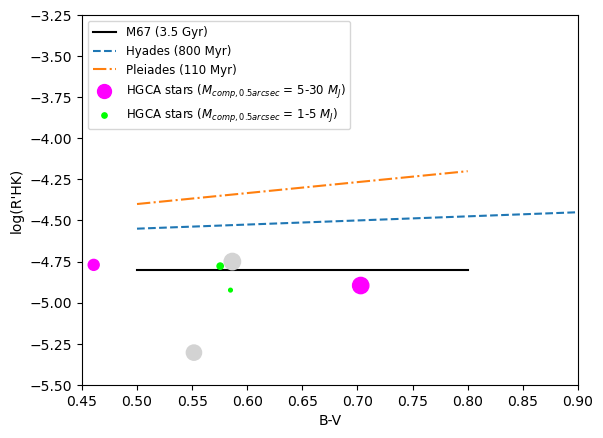

In [5]:
from math import exp, log10

directory='./code/sect3/files/'
file0='gkm_30pctest_plus_gaia_and_cahkv2'
def run(infile=file0):
   table=np.loadtxt(directory+infile,dtype=np.unicode_)
   hgca_name=table[:,0]
   hgca_bmv=table[:,10].astype(float)
   hgca_cahk=table[:,11].astype(float)
   hgca_mass=table[:,2].astype(float)
   hgca_ra=table[:,4].astype(float)
   hgca_dec=table[:,5].astype(float)
   plx=table[:,6].astype(float)

   print(hgca_ra[0:5])
   print(hgca_dec[0:5])

   detectable= np.where( (hgca_mass > 5.0) & (hgca_mass < 30))
   lowmass=np.where((hgca_mass < 5.0) & (hgca_mass > 1.0))
   c1='lightgray'
   m1='.'
   #label1='HGCA stars ($M_{comp, 0.5 arcsec}$ = $1-5 M_{J}$)'

   c2='lime'
   m2='.'
   label2='HGCA stars ($M_{comp, 0.5 arcsec}$ = 1-5 $M_{J}$)'

   c3='magenta'
   m3='.'
   label3='HGCA stars ($M_{comp, 0.5 arcsec}$ = 5-30 $M_{J}$)'
   plt.xlim(0.45,0.9)
   plt.ylim(-5.5,-3.25)
   plt.xlabel("B-V")
   plt.ylabel("log(R'HK)")
   hyades_bmv=[0.5,0.9]
   pleiades_bmv=[0.5,0.8]
   hyades_cahk=[-4.55,-4.45]
   pleiades_cahk=[-4.4,-4.2]
   m67_bmv=[0.5,0.8]
   m67_cahk=[-4.8,-4.8]
   plt.plot(m67_bmv,m67_cahk,'-',zorder=1,label='M67 (3.5 Gyr)',c='black')
   plt.plot(hyades_bmv,hyades_cahk,'--',zorder=1,label='Hyades (800 Myr)')
   plt.plot(pleiades_bmv,pleiades_cahk,'-.',zorder=1,label='Pleiades (110 Myr)')

   plt.scatter(hgca_bmv,hgca_cahk,marker=m1,c=c1,s=30*hgca_mass/2,zorder=2)
   plt.scatter(hgca_bmv[detectable],hgca_cahk[detectable],marker=m3,c=c3,label=label3,s=50*hgca_mass[detectable]/2,zorder=2)
   plt.scatter(hgca_bmv[lowmass],hgca_cahk[lowmass],marker=m2,c=c2,label=label2,s=50*hgca_mass[lowmass]/2,zorder=2)
   plt.legend(loc='upper left',fontsize=8.5)

    
run()

A fuller version of this plot (where I didn't truncate the sample), looks like the following...
                               
![png](./code/sect3/figures/cahk.png)                            